# GAN for Tabular Data Generation
Building a Generative Adversarial Network from scratch in PyTorch

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

torch.manual_seed(42)
np.random.seed(42)

df = pd.read_csv('../data/adult_clean.csv')
print('Shape:', df.shape)
df.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [2]:
# Preprocessing — encode all columns to numerical
df_enc = df.copy()
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(include='number').columns.tolist()

encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))
    encoders[col] = le

scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_enc),
    columns=df_enc.columns
)

data_tensor = torch.FloatTensor(df_scaled.values)
print('Tensor shape:', data_tensor.shape)

with open('../models/gan_encoders.pkl', 'wb') as f:
    pickle.dump(encoders, f)
with open('../models/gan_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open('../models/column_names.pkl', 'wb') as f:
    pickle.dump(df.columns.tolist(), f)

Tensor shape: torch.Size([32561, 15])


In [3]:
# GAN architecture
INPUT_DIM = data_tensor.shape[1]
LATENT_DIM = 128
HIDDEN_DIM = 256

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.BatchNorm1d(HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.BatchNorm1d(HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM),
            nn.Sigmoid()
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(HIDDEN_DIM, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

G = Generator()
D = Discriminator()
print('Generator params:', sum(p.numel() for p in G.parameters()))
print('Discriminator params:', sum(p.numel() for p in D.parameters()))

Generator params: 103695
Discriminator params: 70145


In [4]:
# Training
EPOCHS = 300
BATCH_SIZE = 256
LR = 0.0002

criterion = nn.BCELoss()
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

g_losses, d_losses = [], []

dataset = torch.utils.data.TensorDataset(data_tensor)
loader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

for epoch in range(EPOCHS):
    for (real_batch,) in loader:
        bs = real_batch.size(0)

        # Train Discriminator
        opt_D.zero_grad()
        real_labels = torch.ones(bs, 1)
        fake_labels = torch.zeros(bs, 1)
        z = torch.randn(bs, LATENT_DIM)
        fake = G(z).detach()
        loss_D = criterion(D(real_batch), real_labels) + criterion(D(fake), fake_labels)
        loss_D.backward()
        opt_D.step()

        # Train Generator
        opt_G.zero_grad()
        z = torch.randn(bs, LATENT_DIM)
        fake = G(z)
        loss_G = criterion(D(fake), real_labels)
        loss_G.backward()
        opt_G.step()

    g_losses.append(loss_G.item())
    d_losses.append(loss_D.item())

    if (epoch+1) % 50 == 0:
        print(f'Epoch {epoch+1}/{EPOCHS} | G loss: {loss_G.item():.4f} | D loss: {loss_D.item():.4f}')

print('Training complete!')

Epoch 50/300 | G loss: 0.6999 | D loss: 1.3321


Epoch 100/300 | G loss: 0.7659 | D loss: 1.3254


Epoch 150/300 | G loss: 0.8110 | D loss: 1.3046


Epoch 200/300 | G loss: 0.7446 | D loss: 1.3306


Epoch 250/300 | G loss: 0.7452 | D loss: 1.3776


Epoch 300/300 | G loss: 0.7453 | D loss: 1.3313
Training complete!


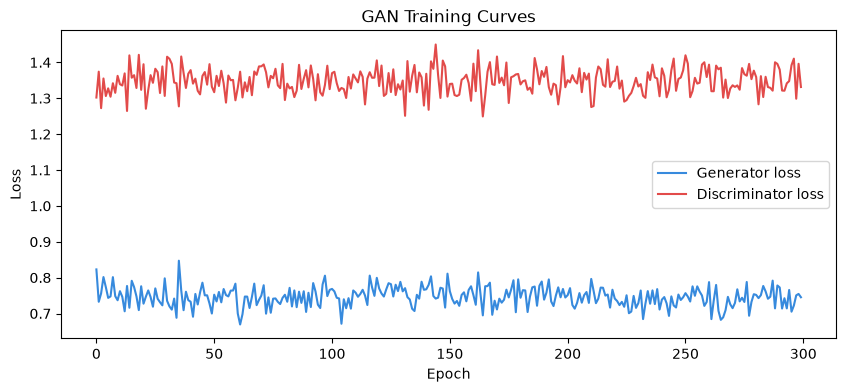

In [5]:
# Plot training curves
plt.figure(figsize=(10, 4))
plt.plot(g_losses, label='Generator loss', color='#378ADD')
plt.plot(d_losses, label='Discriminator loss', color='#E24B4A')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GAN Training Curves')
plt.legend()
plt.savefig('../data/gan_training.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Generate synthetic data
G.eval()
with torch.no_grad():
    z = torch.randn(len(df), LATENT_DIM)
    synthetic_scaled = G(z).numpy()

synthetic_raw = scaler.inverse_transform(synthetic_scaled)
synthetic_df = pd.DataFrame(synthetic_raw, columns=df_enc.columns)

# Decode categorical columns
for col in cat_cols:
    synthetic_df[col] = synthetic_df[col].round().astype(int).clip(
        0, len(encoders[col].classes_)-1
    )
    synthetic_df[col] = encoders[col].inverse_transform(synthetic_df[col])

synthetic_df.to_csv('../data/synthetic_gan.csv', index=False)
torch.save(G.state_dict(), '../models/gan_generator.pt')
print('GAN synthetic data saved:', synthetic_df.shape)
synthetic_df.head()

GAN synthetic data saved: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,45.808979,Private,179942.078125,HS-grad,9.034507,Married-civ-spouse,Transport-moving,Husband,White,Male,40.228310,3.331858e-26,37.611214,United-States,2.615768e-26
1,44.930405,Self-emp-not-inc,349321.125000,HS-grad,9.416117,Married-civ-spouse,Machine-op-inspct,Not-in-family,White,Male,567.585754,7.884887e-15,44.726948,Laos,1.000000e+00
2,39.295227,Private,111725.359375,HS-grad,9.170233,Married-civ-spouse,Armed-Forces,Husband,White,Male,208.681686,1.614337e-27,37.292290,United-States,2.594748e-26
3,17.299862,Private,106661.945312,HS-grad,9.174505,Never-married,Protective-serv,Own-child,White,Female,0.002993,1.198775e-10,13.934333,United-States,1.715253e-33
4,35.599140,Private,425113.656250,Doctorate,13.798348,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,327.244263,1.054981e-07,39.663868,United-States,1.000000e+00
